# Análisis Exploratorio de Datos (AED): campañas de depósitos bancarios

**Metodología:** CRISP-DM · **Fase:** Entendimiento de los datos
**Conjunto:** `bank-full.csv` · 45.211 clientes · 17 columnas (16 predictoras + variable objetivo `y`)


### 1. Librerías y estilo

#### 1.1 Importación de librerías

In [2]:
# Importamos las librerias necesarias para el analiasis de datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter  # Para dar formato a los números de los ejes

#### 1.2 Estilo global

In [3]:
# Estilo: fondo con cuadrícula blanca y colores de paleta "deep"
sns.set_theme(style="whitegrid", context="notebook", palette="deep")

# Tamaños de letra y de figura para todo el cuaderno
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "savefig.dpi": 150,
})

# Formato de las tablas: separadores de miles y dos decimales
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Colores institucionales reutilizables
COLOR_PRINCIPAL = "#1f4e79"    # azul: color de las barras y distribuciones
COLOR_SECUNDARIO = "#c55a11"   # naranja: líneas de referencia y resaltados

print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

pandas 2.3.3 | numpy 2.3.5 | seaborn 0.13.2


In [4]:
!dir

 Volume in drive C is Windows-SSD
 Volume Serial Number is 9CD6-4A19

 Directory of c:\Users\Roger\Videos\Modulo 3\clon 2\TRABAJO-FINAL-_MODULO_3

11/12/2026  08:32 PM    <DIR>          .
11/08/2026  08:58 PM    <DIR>          ..
11/11/2026  06:59 PM    <DIR>          .ipynb_checkpoints
11/12/2026  07:15 PM         1,052,125 AED_1_Analisis_Univariado.ipynb
11/12/2026  08:32 PM                 0 AED_2_Analisis_bivariado.ipynb
11/08/2026  09:15 PM                26 README.md
               3 File(s)      1,052,151 bytes
               3 Dir(s)  33,558,044,672 bytes free


### 2. Carga de datos desde archivos planos (CSV)

In [5]:
# Textos que se consideran "dato faltante" (NaN)
NA_VALUES = ["", "NA", "N/A", "null", "NULL"]

df = pd.read_csv(
    "C:/Users/Roger/Videos/Modulo 3/trabajo final/bank-full.csv",
    sep=";",
    na_values=NA_VALUES,
    keep_default_na=True
)

print("Archivo cargado correctamente.")

Archivo cargado correctamente.


#### 2.1 Dimenciones del conjunto

In [6]:
print("Dimensiones (shape):", df.shape)
print("Número de registros (len):", len(df))
print("Número de columnas:", len(df.columns))

Dimensiones (shape): (45211, 17)
Número de registros (len): 45211
Número de columnas: 17


#### 2.2 Tipos de Datos

In [7]:
print("Tipos de datos (dtypes):")
print(df.dtypes)

Tipos de datos (dtypes):
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object


### 2.3 Existencia de valores nulos

In [8]:
print("Valores nulos reales (NaN) por columna:")
print(df.isna().sum())

Valores nulos reales (NaN) por columna:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


In [9]:
# no hay vacios reales pero hay valores que se consideran vacios como unknown, 0, etc. que se deben tratar de manera diferente.

### 2.4 Primeros registros

In [10]:
df.head(10)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


#### 2.5 Diagnostico de la categoria unknown

In [11]:
# Columnas de texto (no numéricas)
columnas_texto = df.select_dtypes(exclude="number").columns.tolist()

# Cuenta cuántas celdas dicen 'unknown' en cada columna de texto
n_unknown = (df[columnas_texto] == "unknown").sum().sort_values(ascending=False)

diagnostico_unknown = pd.DataFrame({
    "registros_unknown": n_unknown,
    "porcentaje_%": (n_unknown / len(df) * 100).round(2),
})
display(diagnostico_unknown[diagnostico_unknown["registros_unknown"] > 0])

,registros_unknown,porcentaje_%
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64


In [12]:
TRATAR_UNKNOWN_COMO_NULO = False  # Cambiar a True para tratar 'unknown' como dato faltante

if TRATAR_UNKNOWN_COMO_NULO:
    df = df.replace("unknown", np.nan)
    print("'unknown' convertido a NaN.")
else:
    print("'unknown' se conserva como categoría.")

'unknown' se conserva como categoría.


### 2.6 diagnostico de pday

In [13]:
# Conteo y porcentaje de pdays = -1
total = len(df)
n_menos_uno = (df["pdays"] == -1).sum()
pct_menos_uno = n_menos_uno / total * 100

print(f"Total de clientes: {total:,}")
print(f"Clientes con pdays = -1: {n_menos_uno:,} ({pct_menos_uno:.2f} %)")

# Resto de los valores (clientes con contacto previo)
n_contactados = total - n_menos_uno
print(f"Clientes con pdays distinto de -1: {n_contactados:,} ({100 - pct_menos_uno:.2f} %)")

Total de clientes: 45,211
Clientes con pdays = -1: 36,954 (81.74 %)
Clientes con pdays distinto de -1: 8,257 (18.26 %)


### 3. Variables Cualitativas (univariado)
Antes de analizar cada variable, se definen dos funciones que se usan en todas.

In [14]:
def resumen_frecuencias(serie):
    # Tabla con la cantidad y el porcentaje de cada categoría
    frecuencia = serie.value_counts(dropna=False)
    porcentaje = serie.value_counts(normalize=True, dropna=False) * 100
    return pd.DataFrame({"frecuencia": frecuencia, "porcentaje_%": porcentaje.round(2)})

In [15]:
def grafico_barras(serie, titulo, etiqueta_x, orden=None, color=COLOR_PRINCIPAL):
    # Dibuja un gráfico de barras con anotaciones de cantidad y porcentaje
    conteo = serie.value_counts(dropna=False)
    
    if orden is not None:
        conteo = conteo.reindex(orden).dropna()  # Solo actúa si 'orden' fue proveído
        total = conteo.sum()
    else:
        total = conteo.sum()

    fig, ax = plt.subplots(figsize=(11, 6))
    sns.barplot(x=conteo.index.astype(str), y=conteo.values, color=color, ax=ax)

    # Escribe "cantidad (porcentaje)" encima de cada barra
    for i, valor in enumerate(conteo.values):
        ax.annotate(f"{valor:,}\n({valor / total:.1%})", (i, valor),
                    ha="center", va="bottom", fontsize=9,
                    xytext=(0, 3), textcoords="offset points")

    ax.set_title(titulo, pad=15)
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel("Número de clientes")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
    ax.set_ylim(0, conteo.max() * 1.18)  # Deja espacio para las anotaciones
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")  # Evita que se encimen
    sns.despine(left=True)
    plt.tight_layout()
    plt.show()

#### 3.1 Ocupacion de los clientes

Tabla de frecuencias: ocupación


,frecuencia,porcentaje_%
job,,
blue-collar,9732,21.53
management,9458,20.92
technician,7597,16.80
admin.,5171,11.44
services,4154,9.19
retired,2264,5.01
self-employed,1579,3.49
entrepreneur,1487,3.29
unemployed,1303,2.88


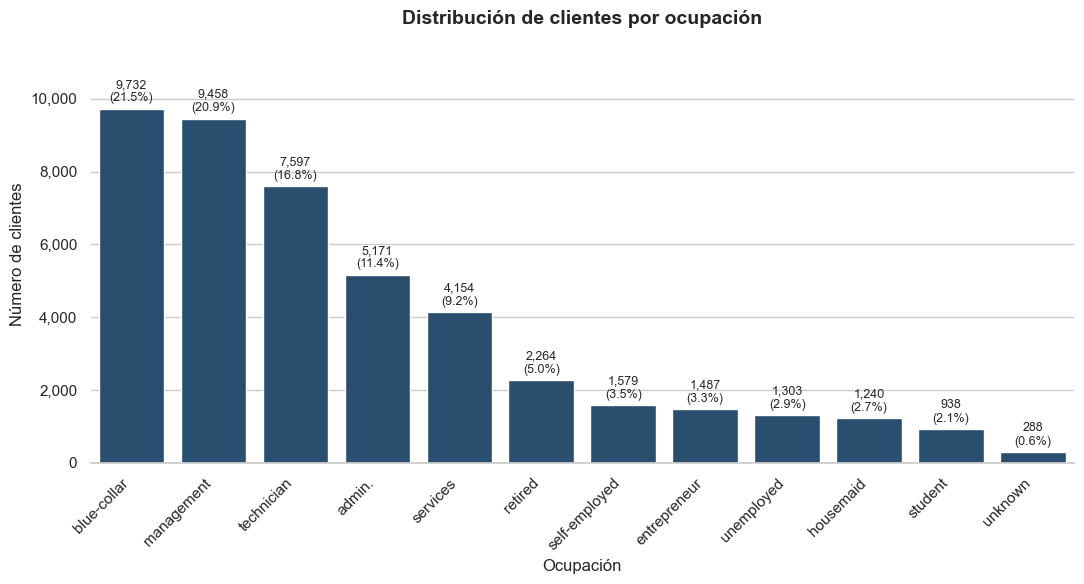

In [16]:
print("Tabla de frecuencias: ocupación")
display(resumen_frecuencias(df["job"]))

grafico_barras(df["job"], "Distribución de clientes por ocupación", "Ocupación")

#### 3.2 Estado civil

Tabla de frecuencias: estado civil


,frecuencia,porcentaje_%
marital,,
married,27214,60.19
single,12790,28.29
divorced,5207,11.52


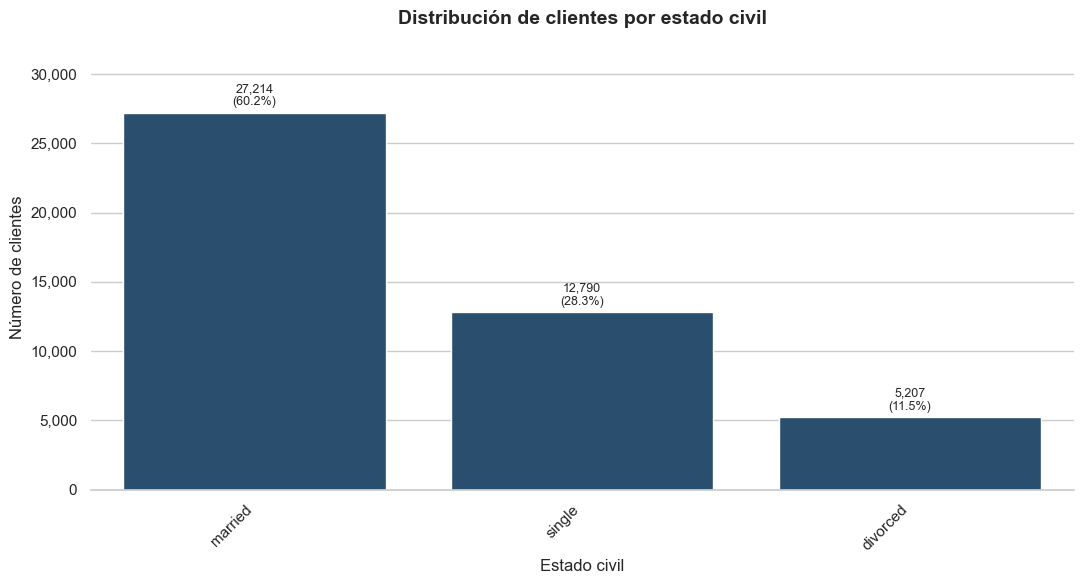

In [17]:
print("Tabla de frecuencias: estado civil")
display(resumen_frecuencias(df["marital"]))

grafico_barras(df["marital"], "Distribución de clientes por estado civil", "Estado civil")

**Cómo interpretarlo.** Seis de cada diez clientes están **casados (60,2 %)**. Solo 11,5 % son divorciados.

#### 3.3 Nivel educativo (`education`)

Tabla de frecuencias: nivel educativo


,frecuencia,porcentaje_%
education,,
secondary,23202,51.32
tertiary,13301,29.42
primary,6851,15.15
unknown,1857,4.11


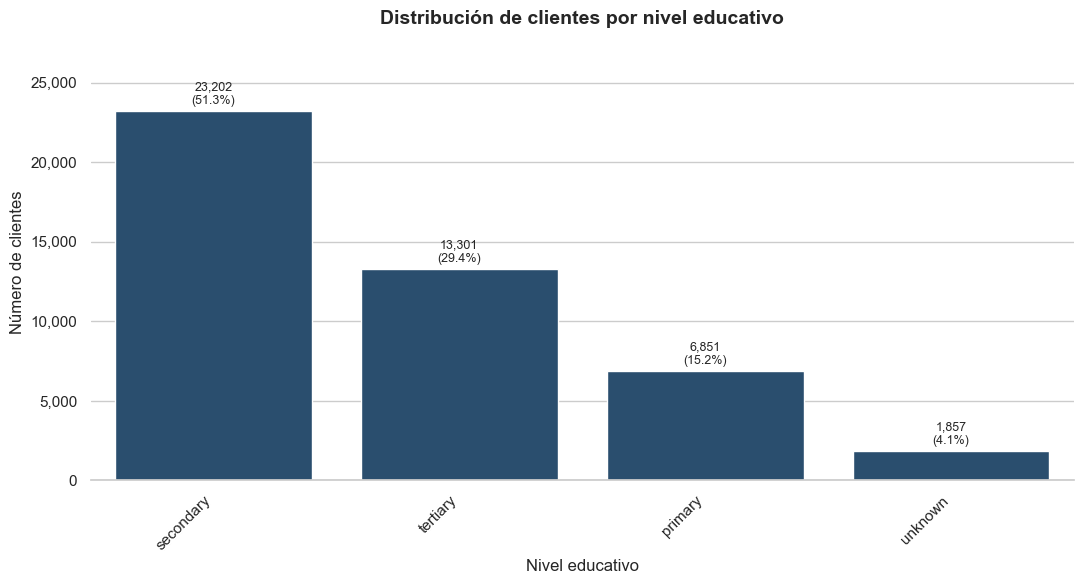

In [18]:
print("Tabla de frecuencias: nivel educativo")
display(resumen_frecuencias(df["education"]))

grafico_barras(df["education"], "Distribución de clientes por nivel educativo", "Nivel educativo")

**Cómo interpretarlo.** La mitad tiene **secundaria (51,3 %)**. Un 29,4 % tiene educación superior. Un 4,1 % está como `unknown`.

#### 3.4 Crédito en incumplimiento (`default`)

Tabla de frecuencias: crédito en incumplimiento


,frecuencia,porcentaje_%
default,,
no,44396,98.20
yes,815,1.80


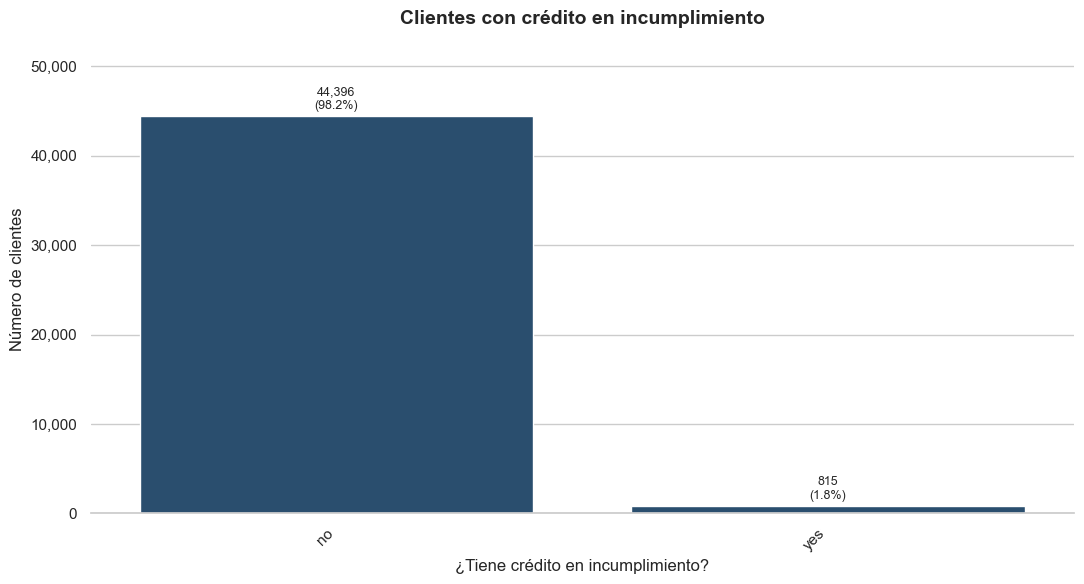

In [19]:
print("Tabla de frecuencias: crédito en incumplimiento")
display(resumen_frecuencias(df["default"]))

grafico_barras(df["default"], "Clientes con crédito en incumplimiento", "¿Tiene crédito en incumplimiento?")

**¿Para qué sirve?** Medir qué tan frecuente es el riesgo de impago en la base.

**Cómo interpretarlo.** Casi nadie está en esta situación: solo **1,8 %** (815 clientes). Como casi todos son "no", esta variable aporta poca información para distinguir clientes.

####  3.5 Préstamo de vivienda (`housing`)

Tabla de frecuencias: préstamo de vivienda


,frecuencia,porcentaje_%
housing,,
yes,25130,55.58
no,20081,44.42


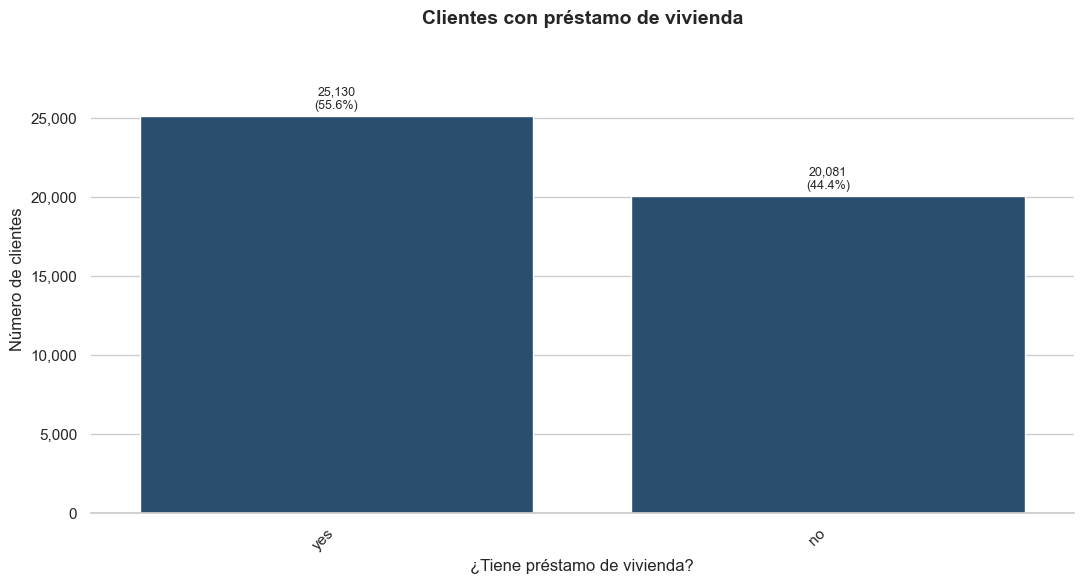

In [20]:
print("Tabla de frecuencias: préstamo de vivienda")
display(resumen_frecuencias(df["housing"]))

grafico_barras(df["housing"], "Clientes con préstamo de vivienda", "¿Tiene préstamo de vivienda?")

**¿Qué es?** Si el cliente tiene una hipoteca o préstamo para su casa.

**¿Para qué sirve?** Saber qué proporción de clientes tiene deudas de vivienda.

**Cómo interpretarlo.** Más de la mitad tiene **préstamo de vivienda (55,6 %)**. Esto es importante porque más adelante se verá que esta variable se relaciona con la contratación.

#### 3.6 Préstamo personal (`loan`)

Tabla de frecuencias: préstamo personal


,frecuencia,porcentaje_%
loan,,
no,37967,83.98
yes,7244,16.02


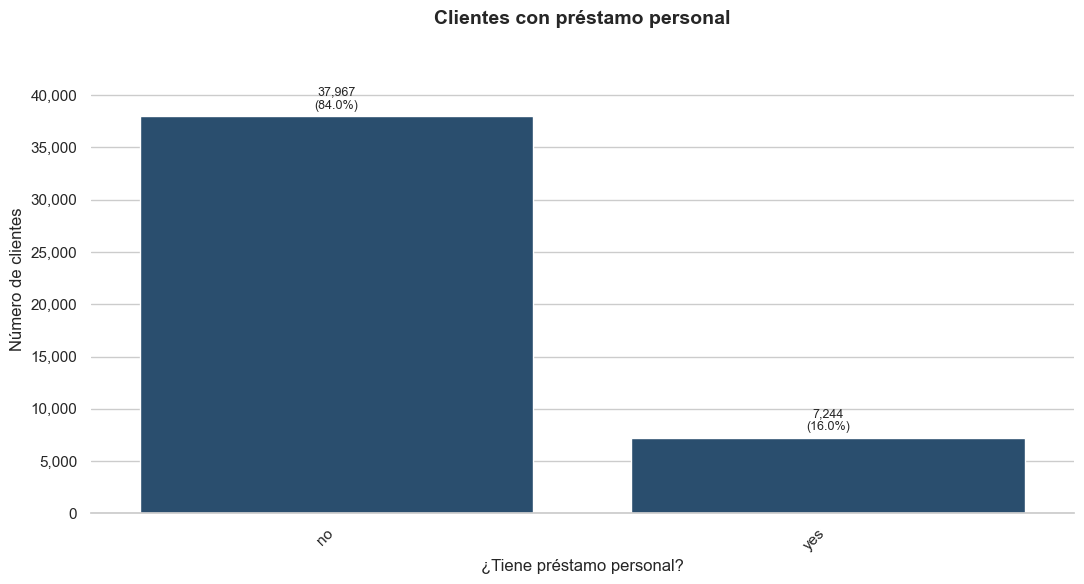

In [21]:
print("Tabla de frecuencias: préstamo personal")
display(resumen_frecuencias(df["loan"]))

grafico_barras(df["loan"], "Clientes con préstamo personal", "¿Tiene préstamo personal?")

**¿Qué es?** Si el cliente tiene un préstamo personal (no hipotecario).

**¿Para qué sirve?** Ver cuántos clientes tienen otra deuda activa.

**Cómo interpretarlo.** Solo **16 %** tiene préstamo personal. La mayoría (84 %) no tiene.

#### 3.7 Canal de contacto (`contact`)

Tabla de frecuencias: canal de contacto


,frecuencia,porcentaje_%
contact,,
cellular,29285,64.77
unknown,13020,28.80
telephone,2906,6.43


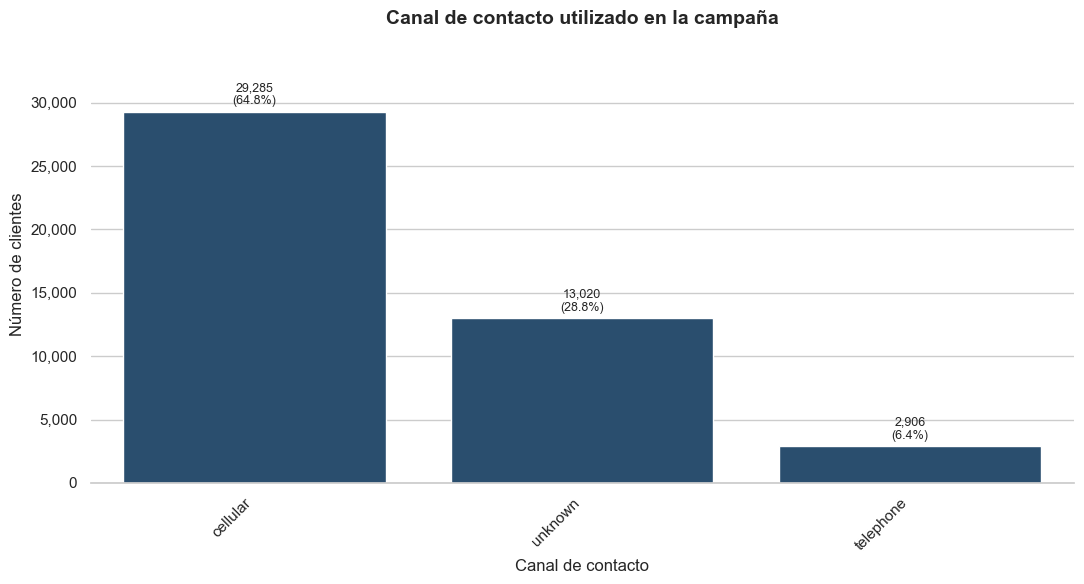

In [22]:
print("Tabla de frecuencias: canal de contacto")
display(resumen_frecuencias(df["contact"]))

grafico_barras(df["contact"], "Canal de contacto utilizado en la campaña", "Canal de contacto")

**¿Qué es?** El medio por el que el banco llamó al cliente en el último contacto: celular, teléfono fijo o desconocido.

**¿Para qué sirve?** Ver qué canal se usó más en la campaña.

**Cómo interpretarlo.** El **celular (64,8 %)** es el canal dominante. El **28,8 % está como `unknown`**, un porcentaje alto que conviene tener presente.

#### 3.8 Mes del último contacto (`month`)

Tabla de frecuencias: mes del último contacto


,frecuencia,porcentaje_%
month,,
may,13766,30.45
jul,6895,15.25
aug,6247,13.82
jun,5341,11.81
nov,3970,8.78
apr,2932,6.49
feb,2649,5.86
jan,1403,3.10
oct,738,1.63


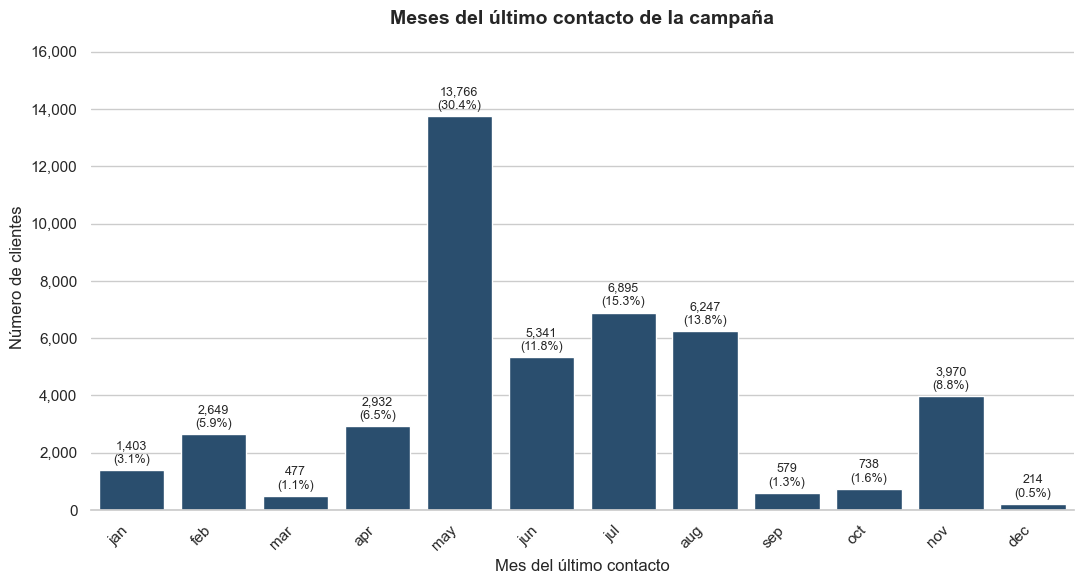

In [23]:
ORDEN_MESES = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

print("Tabla de frecuencias: mes del último contacto")
display(resumen_frecuencias(df["month"]))

grafico_barras(df["month"], "Meses del último contacto de la campaña", "Mes del último contacto",
               orden=ORDEN_MESES)

**¿Qué es?** El mes en que se hizo el último contacto con el cliente.

**¿Para qué sirve?** Ver en qué meses se concentró la campaña.

**Cómo interpretarlo.** **Mayo** domina con **30,5 %** de los contactos. Julio y agosto siguen (15 % y 14 %). Diciembre, octubre y septiembre casi no tienen contactos (menos de 2 % cada uno). El banco llamó mucho más en unos meses que en otros.

#### 3.9 Resultado de la campaña anterior (`poutcome`)

Tabla de frecuencias: resultado de la campaña anterior


,frecuencia,porcentaje_%
poutcome,,
unknown,36959,81.75
failure,4901,10.84
other,1840,4.07
success,1511,3.34


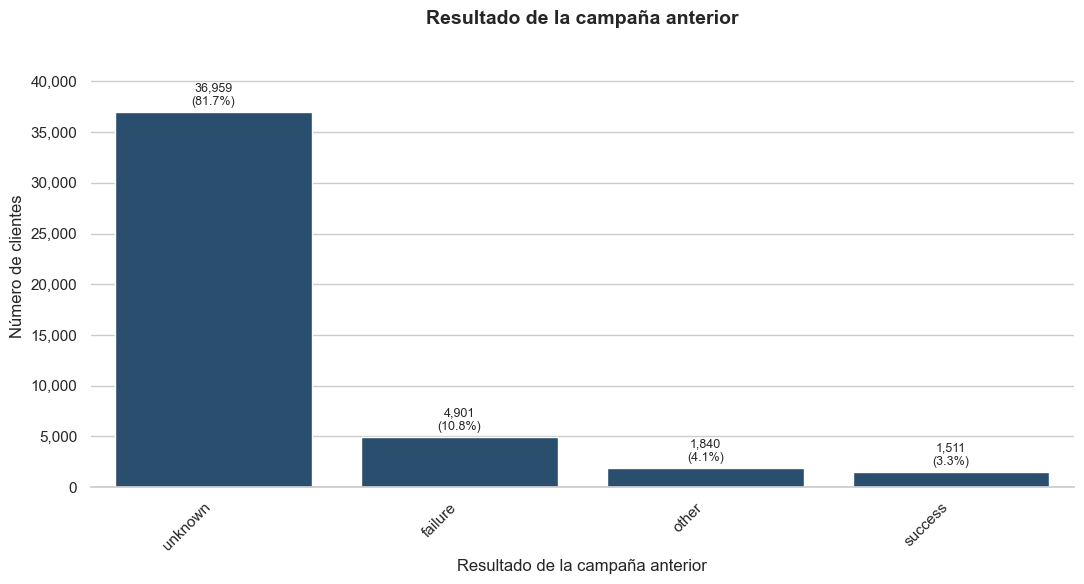

In [24]:
print("Tabla de frecuencias: resultado de la campaña anterior")
display(resumen_frecuencias(df["poutcome"]))

grafico_barras(df["poutcome"], "Resultado de la campaña anterior", "Resultado de la campaña anterior")

**¿Qué es?** Cómo resultó la campaña anterior con ese mismo cliente: éxito, fracaso, otro o desconocido.

**¿Para qué sirve?** Saber si los clientes ya habían respondido bien antes.

**Cómo interpretarlo.** El **81,8 % es `unknown`**: para la mayoría no hubo campaña previa. Solo **3,3 %** (1.511 clientes) tuvo éxito antes. Como casi todo es desconocido, es una variable con pocos datos útiles.

### 3.10 Variable objetivo (`y`)

Tabla de frecuencias: variable objetivo


,frecuencia,porcentaje_%
y,,
no,39922,88.30
yes,5289,11.70


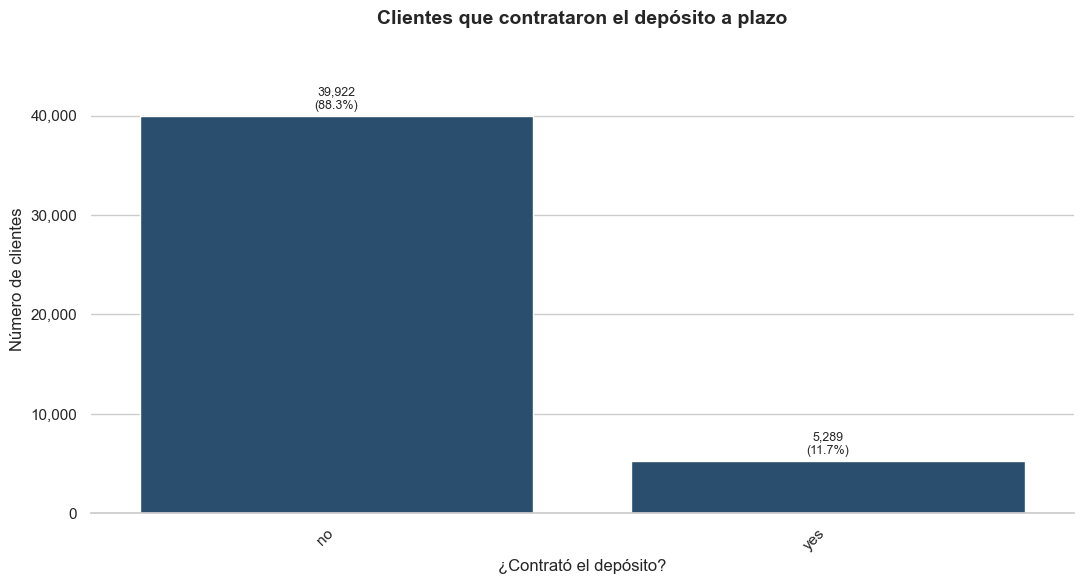

In [25]:
print("Tabla de frecuencias: variable objetivo")
display(resumen_frecuencias(df["y"]))

grafico_barras(df["y"], "Clientes que contrataron el depósito a plazo", "¿Contrató el depósito?")

### 4. Variables Cuantitativas (univariado)

Una variable numérica tiene valores que se pueden medir y comparar (edad, saldo, duración). Para describirla se usan medidas de **centro** (dónde está la mayoría), **dispersión** (qué tan separados están los valores) y **forma** (si hay valores extremos).

### 4.1 Función de estadísticas
**¿Qué es?** Una función que calcula todas las medidas de la tabla anterior para una variable.

**¿Para qué sirve?** Obtener un resumen completo de cualquier variable numérica en una sola línea.

**Cómo interpretarlo.** Ver la tabla de resultados en la celda siguiente.

In [26]:
def estadisticas_univariadas(serie):
    # Calcula tendencia central, dispersión y atípicos de una variable numérica
    s = serie.dropna()
    q1, q2, q3 = s.quantile([0.25, 0.5, 0.75])
    ric = q3 - q1
    moda = s.mode()
    media = s.mean()
    limite_inf, limite_sup = q1 - 1.5 * ric, q3 + 1.5 * ric
    return {
        "Media": media,
        "Mediana": q2,
        "Moda": moda.iloc[0] if not moda.empty else np.nan,
        "Mínimo": s.min(),
        "Máximo": s.max(),
        "Rango": s.max() - s.min(),
        "Q1 (25%)": q1,
        "Q3 (75%)": q3,
        "RIC (Q3 - Q1)": ric,
        "Varianza": s.var(),
        "Desv. estándar": s.std(),
        "Coef. variación %": (s.std() / media * 100) if media != 0 else np.nan,
        "Atípicos (Tukey)": int(((s < limite_inf) | (s > limite_sup)).sum()),
    }

### 4.2 Tabla de estadísticas de todas las variables numéricas
**¿Qué es?** Aplica la función anterior a cada variable numérica y arma una tabla comparativa.

**¿Para qué sirve?** Comparar las variables de un vistazo.

**Cómo interpretarlo.**

- **Edad:** media 40,9 y mediana 39. Va de 18 a 95 años, con poca dispersión relativa (desviación de 10,6 años). Solo 1 % son atípicos (mayores extremos).
- **Saldo (`balance`):** la **media (1.362 €) triplica la mediana (448 €)**. Esto indica que unos pocos clientes con saldos muy altos (hasta 102.127 €) elevan el promedio. Hay **10,5 % de atípicos**, y 8,3 % tiene saldo negativo.
- **Día (`day`):** va del 1 al 31 sin valores atípicos. Los contactos se repartieron de forma pareja a lo largo del mes.
- **Duración (`duration`):** mediana de 180 segundos (3 minutos), con 7 % de atípicos. Hay llamadas de casi 82 minutos.
- **Campañas (`campaign`):** la mediana es 2 contactos, pero el máximo llega a 63. El **6,8 % fueron atípicos**, es decir, clientes contactados muchas veces.
- **Días desde contacto previo (`pdays`):** el valor -1 significa "nunca contactado". Por eso la media (40) no es útil. Se analiza aparte en el paso 5.3.
- **Contactos previos (`previous`):** la mediana es 0. El 18 % tuvo contacto previo y el resto no.

In [27]:
CUANTITATIVAS = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]

tabla_estadisticas = pd.DataFrame(
    {columna: estadisticas_univariadas(df[columna]) for columna in CUANTITATIVAS}
).T
display(tabla_estadisticas)

,Media,Mediana,Moda,Mínimo,Máximo,Rango,Q1 (25%),Q3 (75%),RIC (Q3 - Q1),Varianza,Desv. estándar,Coef. variación %,Atípicos (Tukey)
age,40.94,39.00,32.00,18.00,95.00,77.00,33.00,48.00,15.00,112.76,10.62,25.94,487.00
balance,"1,362.27",448.00,0.00,"-8,019.00","102,127.00","110,146.00",72.00,"1,428.00","1,356.00","9,270,598.95","3,044.77",223.51,"4,729.00"
day,15.81,16.00,20.00,1.00,31.00,30.00,8.00,21.00,13.00,69.26,8.32,52.65,0.00
duration,258.16,180.00,124.00,0.00,"4,918.00","4,918.00",103.00,319.00,216.00,"66,320.57",257.53,99.75,"3,235.00"
campaign,2.76,2.00,1.00,1.00,63.00,62.00,1.00,3.00,2.00,9.60,3.10,112.09,"3,064.00"
pdays,40.20,-1.00,-1.00,-1.00,871.00,872.00,-1.00,-1.00,0.00,"10,025.77",100.13,249.09,"8,257.00"
previous,0.58,0.00,0.00,0.00,275.00,275.00,0.00,0.00,0.00,5.31,2.30,396.92,"8,257.00"


### 4.3 Función de histograma
**¿Qué es?** Un histograma divide los valores en intervalos (barras) y cuenta cuántos caen en cada uno. La línea suave (KDE) muestra la forma general. La línea discontinua marca la **media** y la punteada la **mediana**.

**¿Para qué sirve?** Ver la **forma** de la distribución: si está centrada, si está sesgada hacia un lado y si tiene dos picos.

**Cómo interpretarlo.**
- **Simétrica:** media y mediana casi iguales.
- **Sesgada a la derecha:** la media queda más a la derecha que la mediana. Hay valores altos que la empujan.
- **Sesgada a la izquierda:** lo contrario.

In [28]:
def histograma(serie, titulo, etiqueta_x, color=COLOR_PRINCIPAL):
    # Dibuja un histograma con curva KDE, media y mediana
    s = serie.dropna()
    media, mediana = s.mean(), s.median()

    fig, ax = plt.subplots(figsize=(10, 5.5))
    sns.histplot(s, bins=40, kde=True, color=color, edgecolor="white", ax=ax)
    ax.axvline(media, color=COLOR_SECUNDARIO, linestyle="--", linewidth=2,
               label=f"Media = {media:,.1f}")
    ax.axvline(mediana, color="black", linestyle=":", linewidth=2,
               label=f"Mediana = {mediana:,.1f}")
    ax.set_title(titulo, pad=15)
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel("Frecuencia (número de clientes)")
    ax.legend(frameon=False)
    sns.despine()
    plt.tight_layout()
    plt.show()

### 4.4 Histograma de edad(`age`)

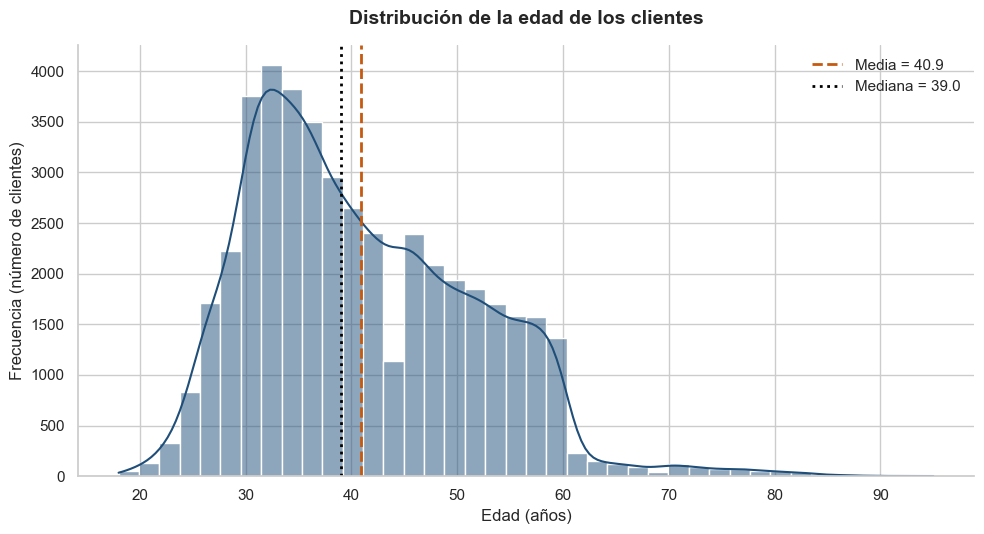

In [29]:
histograma(df["age"], "Distribución de la edad de los clientes", "Edad (años)")

**¿Qué es?** La distribución de la edad de los clientes.

**¿Para qué sirve?** Ver en qué rango de edad se concentra la base.

**Cómo interpretarlo.** La mayoría tiene entre 30 y 50 años. La cola a la derecha es larga, pero la media (40,9) y la mediana (39) están cerca: la distribución es casi simétrica, con una leve inclinación hacia edades mayores.

### 4.5 Histograma de saldo (`balance`)

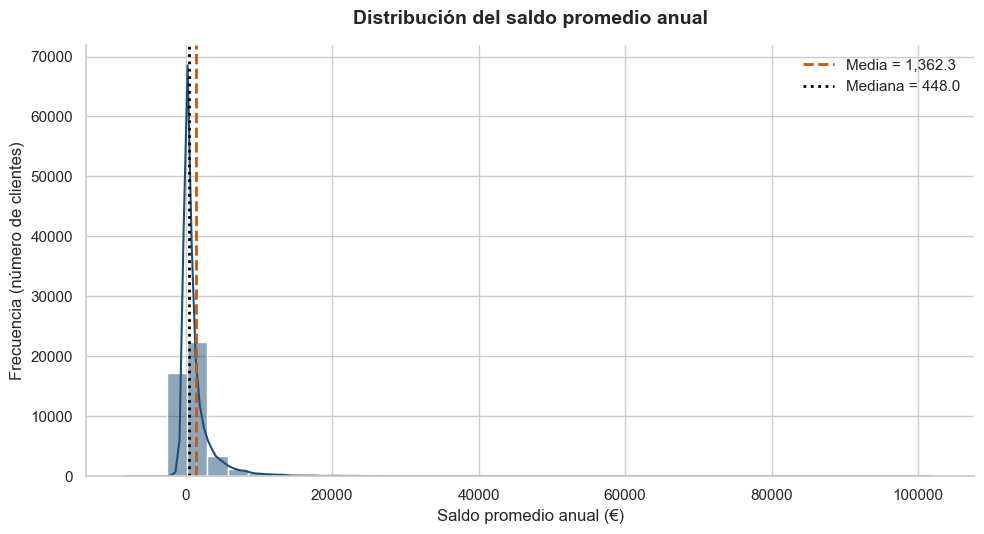

In [30]:
histograma(df["balance"], "Distribución del saldo promedio anual", "Saldo promedio anual (€)")

**¿Qué es?** La distribución del saldo promedio anual, en euros.

**¿Para qué sirve?** Ver cómo se reparten los saldos entre los clientes.

**Cómo interpretarlo.** La gran mayoría tiene saldos bajos, y unos pocos tienen saldos muy altos. Por eso la **media (1.362 €) queda muy por encima de la mediana (448 €)**. Es una distribución **sesgada a la derecha**: para describir "un cliente típico", la mediana es mejor medida que la media.

#### 4.6 Histograma del día del mes(`day`)

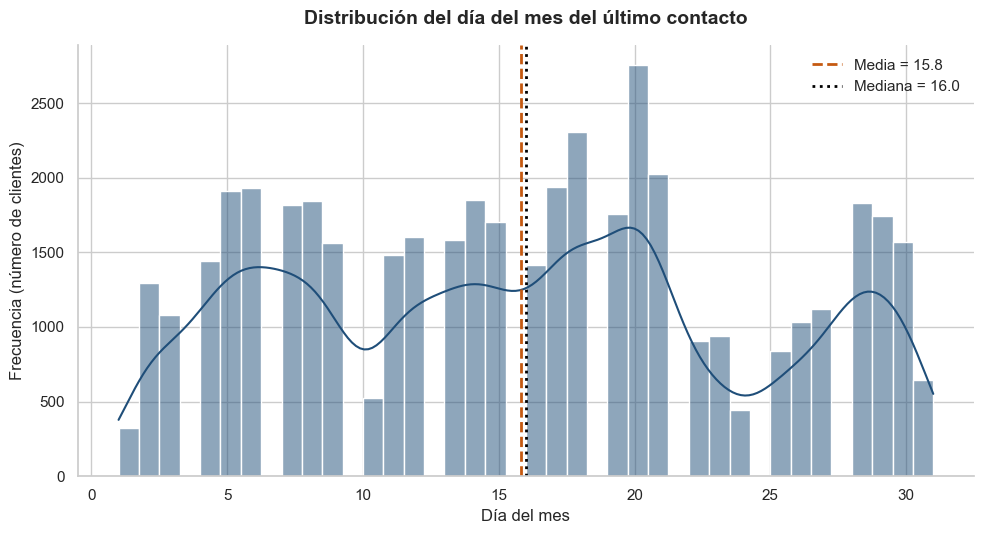

In [31]:
histograma(df["day"], "Distribución del día del mes del último contacto", "Día del mes")

**¿Qué es?** En qué día del mes se hizo el último contacto.

**¿Para qué sirve?** Ver si las llamadas se concentran en algunos días.

**Cómo interpretarlo.** La distribución es bastante pareja a lo largo del mes, sin días concentrados de forma notable. Esta variable aporta poca información por sí sola.

#### 4.7 Histograma de duración(`duration`)

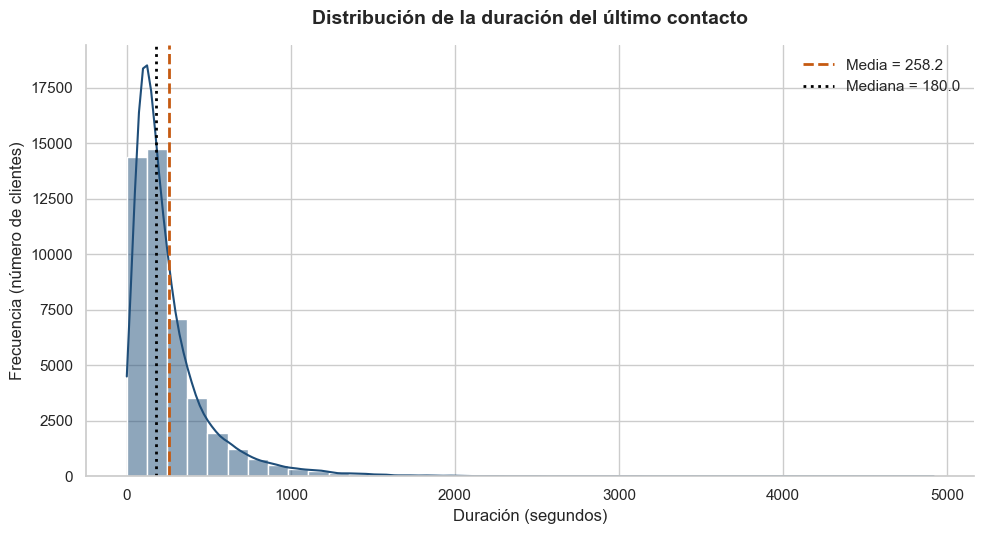

In [32]:
histograma(df["duration"], "Distribución de la duración del último contacto", "Duración (segundos)")

**¿Qué es?** Cuánto duró la última llamada, en segundos.

**¿Para qué sirve?** Ver el tiempo típico de una llamada.

**Cómo interpretarlo.** La mayoría de llamadas son cortas, con mediana de 3 minutos. La distribución tiene una cola larga hacia la derecha: hay llamadas de más de una hora. **Advertencia:** esta variable solo se conoce después de la llamada, así que no sirve para decidir a quién llamar.

### 4.8 Histograma de número de contactos(`campaign`)

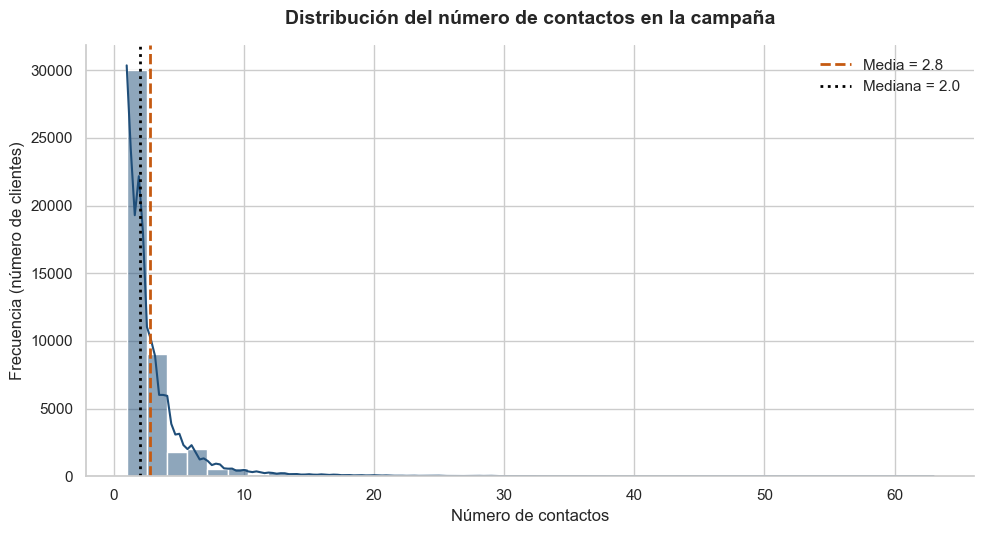

In [33]:
histograma(df["campaign"], "Distribución del número de contactos en la campaña", "Número de contactos")

**¿Qué es?** Cuántas veces se contactó al cliente en esta campaña.

**¿Para qué sirve?** Ver si la mayoría recibió pocos contactos o muchos.

**Cómo interpretarlo.** La mayoría recibió **1 a 3 contactos** (mediana de 2). Hay casos extremos con más de 40 contactos, lo que se ve en la cola larga a la derecha

### 4.9 Histograma de contactos previos(`previous`)

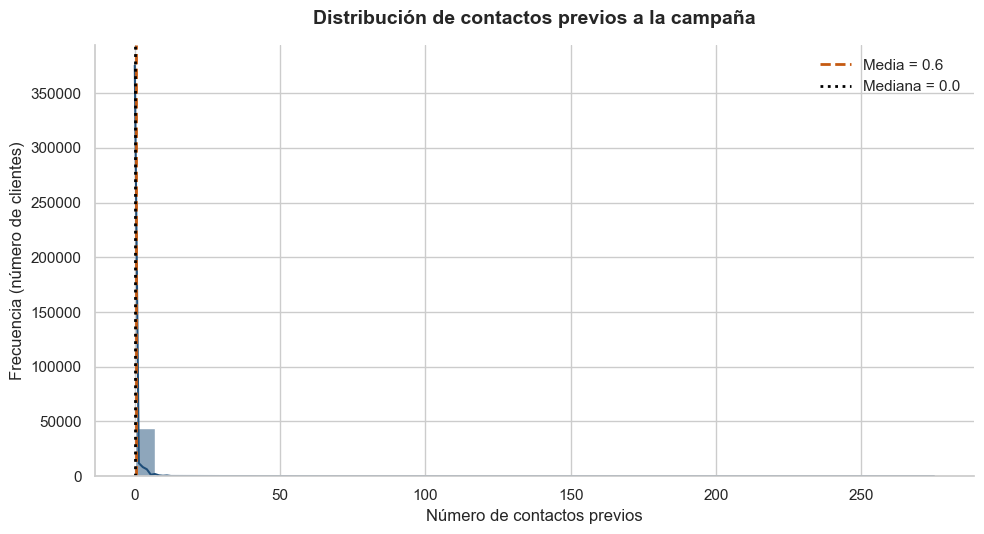

In [34]:
histograma(df["previous"], "Distribución de contactos previos a la campaña", "Número de contactos previos")

**¿Qué es?** Cuántas veces se había contactado al cliente antes de esta campaña.

**¿Para qué sirve?** Ver qué tan común es tener historial con el banco.

**Cómo interpretarlo.** La gran mayoría tiene **cero** contactos previos. Es una distribución muy concentrada en el 0, con pocos casos con historial largo.

### 4.10 Diagramas de caja
**¿Qué es?** Un diagrama de caja muestra la mediana (línea central), la caja (del Q1 al Q3, que contiene el 50 % central) y los **bigotes**. Los puntos fuera de los bigotes son **atípicos**.

**¿Para qué sirve?** Detectar valores extremos de un vistazo y comparar la dispersión entre variables.

**Cómo interpretarlo.** Una caja pequeña significa que la mayoría de los valores son parecidos. Muchos puntos por fuera indican valores extremos. En este caso `balance`, `duration` y `campaign` tienen muchos atípicos, mientras que `day` no tiene ninguno.

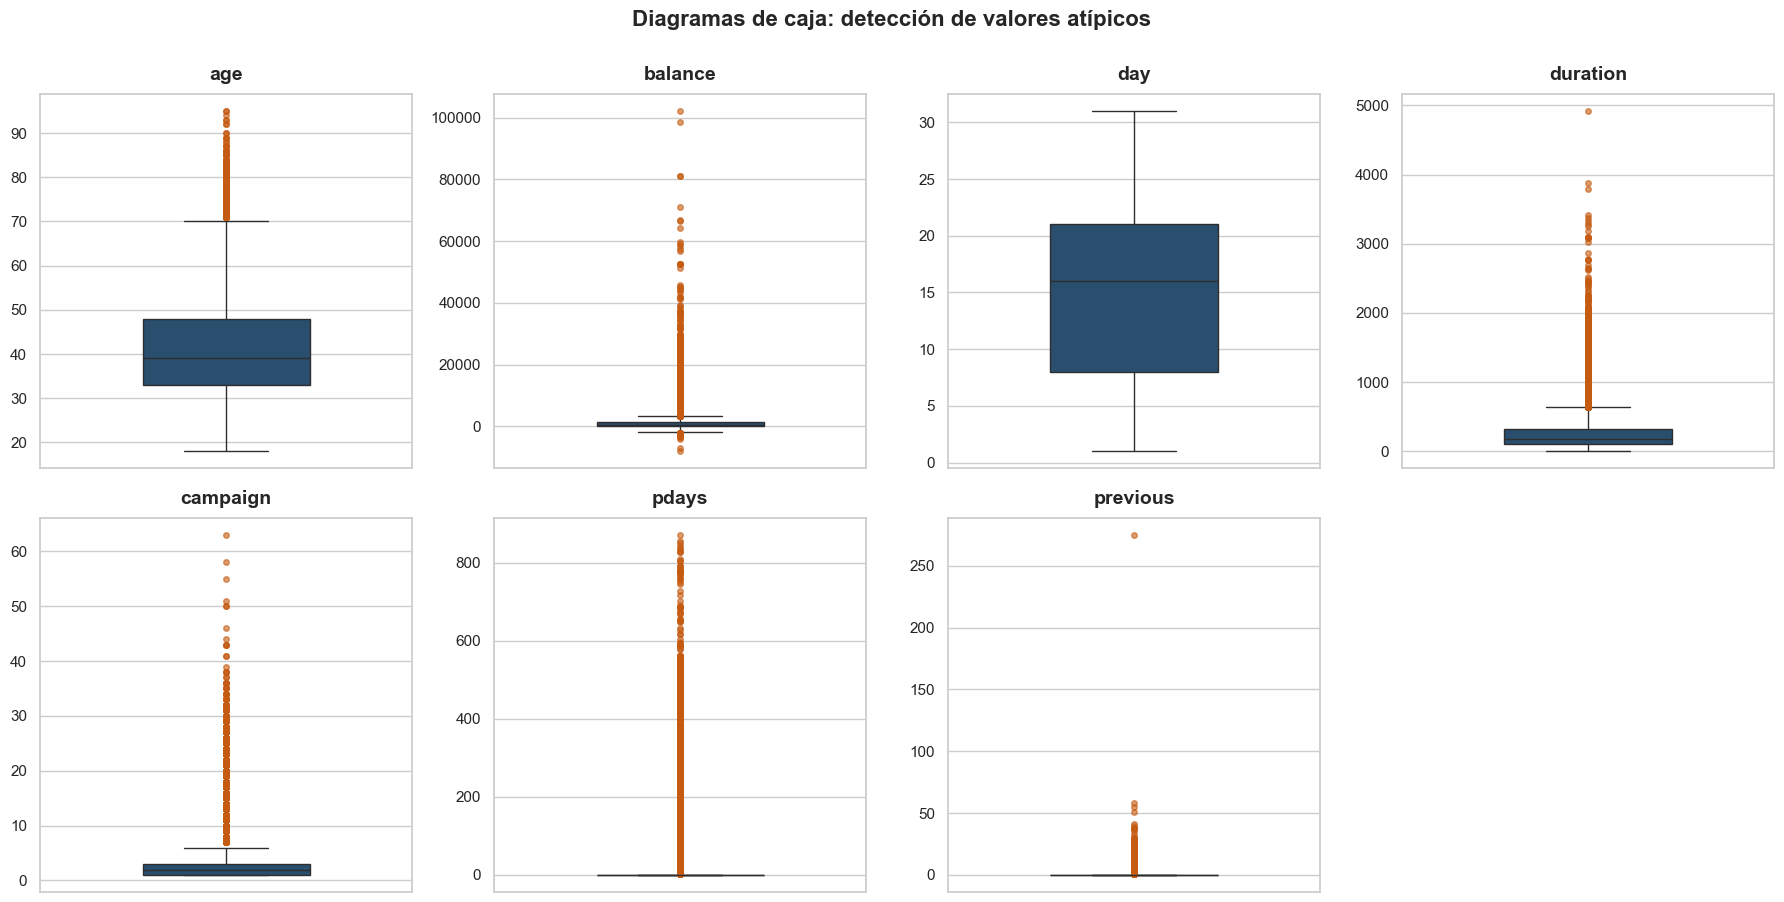

In [35]:
fig, ejes = plt.subplots(2, 4, figsize=(18, 9))
ejes = ejes.flatten()

for ax, columna in zip(ejes, CUANTITATIVAS):
    sns.boxplot(y=df[columna].dropna(), color=COLOR_PRINCIPAL, width=0.45,
                flierprops={"marker": "o", "markerfacecolor": COLOR_SECUNDARIO,
                            "markeredgecolor": COLOR_SECUNDARIO, "markersize": 4, "alpha": 0.6},
                ax=ax)
    ax.set_title(columna, pad=10)
    ax.set_ylabel("")

ejes[-1].set_visible(False)  # Oculta el espacio sobrante de la cuadrícula
fig.suptitle("Diagramas de caja: detección de valores atípicos", fontsize=16,
             fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

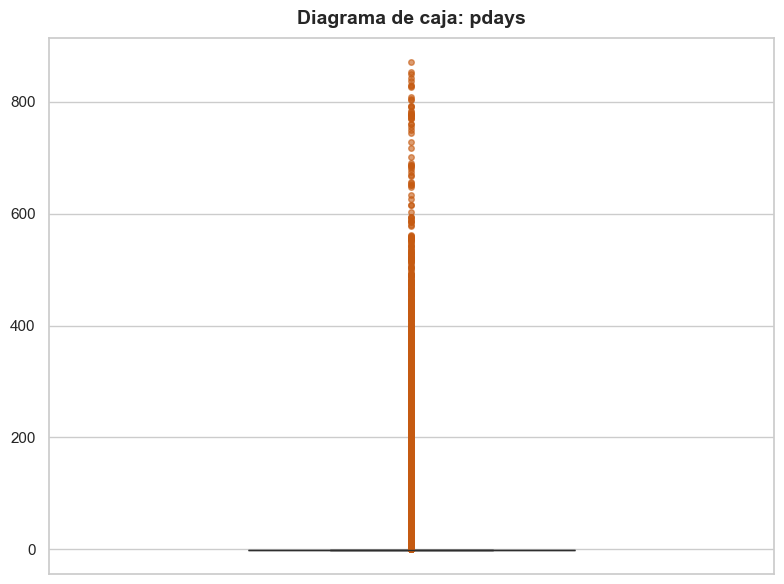

In [36]:
# 1. Creamos una figura individual con un tamaño cómodo
plt.figure(figsize=(8, 6))
# 2. Generamos el boxplot exclusivo para 'pdays'
sns.boxplot(
    y=df["pdays"].dropna(),
    color=COLOR_PRINCIPAL,
    width=0.45,
    flierprops={
        "marker": "o",
        "markerfacecolor": COLOR_SECUNDARIO,
        "markeredgecolor": COLOR_SECUNDARIO,
        "markersize": 4,
        "alpha": 0.6,
    },
)
# 3. Configuramos el título y los ejes
plt.title("Diagrama de caja: pdays", fontsize=14, fontweight="bold", pad=10)
plt.ylabel("")
# 4. Mostramos el gráfico
plt.tight_layout()
plt.show()

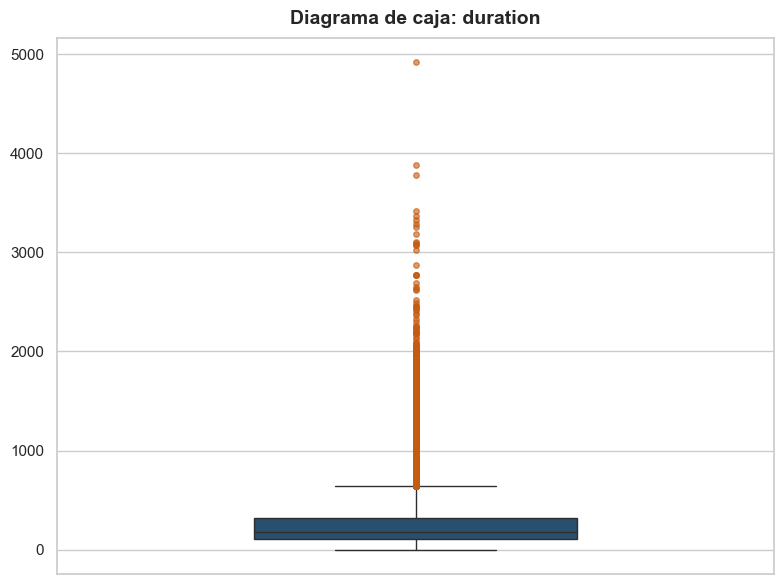

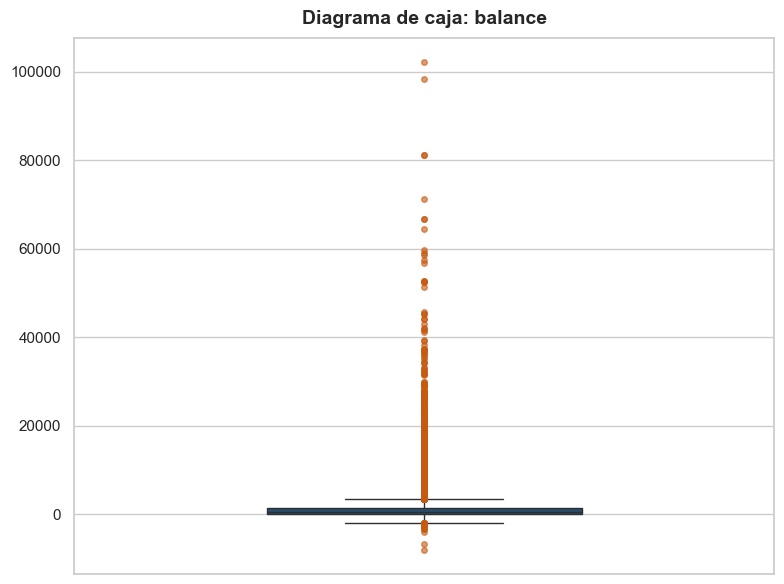

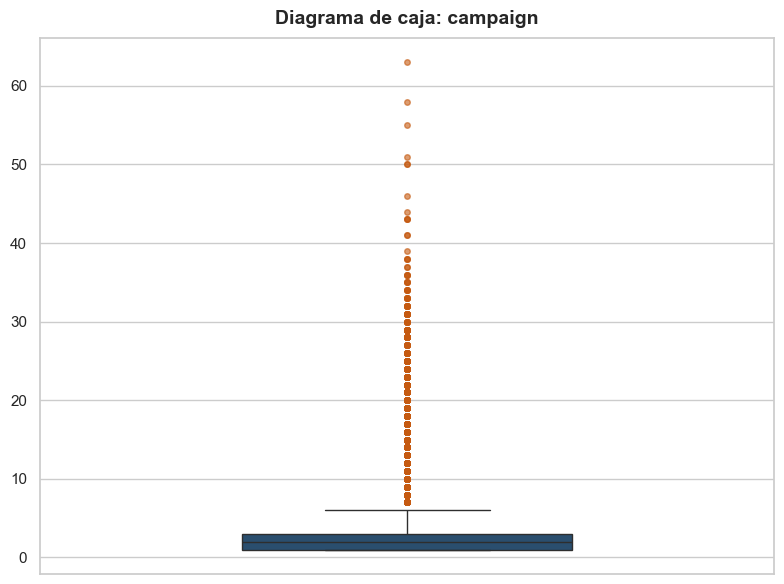

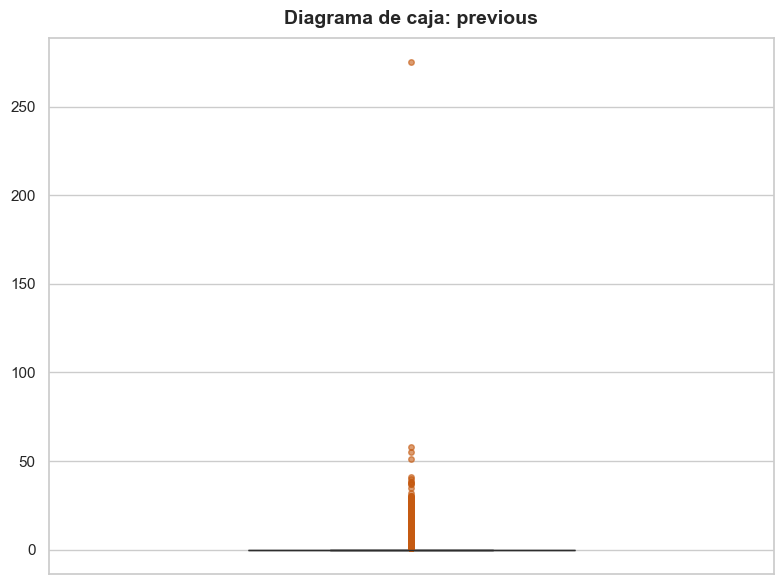

In [37]:
# Lista con las variables que quieres graficar por separado
VARIABLES = ["duration", "balance", "campaign", "previous"]

# Generamos un gráfico individual para cada variable
for columna in VARIABLES:
    plt.figure(figsize=(8, 6))

    sns.boxplot(
        y=df[columna].dropna(),
        color=COLOR_PRINCIPAL,
        width=0.45,
        flierprops={
            "marker": "o",
            "markerfacecolor": COLOR_SECUNDARIO,
            "markeredgecolor": COLOR_SECUNDARIO,
            "markersize": 4,
            "alpha": 0.6,
        },
    )

    plt.title(
        f"Diagrama de caja: {columna}", fontsize=14, fontweight="bold", pad=10
    )
    plt.ylabel("")

    plt.tight_layout()
    plt.show()

## 5. Perfilado automático (opcional)

### 5.1 Reporte con ydata-profiling
**¿Qué es?** Una herramienta que analiza automáticamente todo el conjunto y genera un reporte HTML con distribuciones, correlaciones, valores faltantes y alertas de calidad.

**¿Para qué sirve?** Confirmar en segundos lo que se hizo a mano en este cuaderno y descubrir cosas que se hayan pasado por alto. Requiere `pip install ydata-profiling`.

**Cómo interpretarlo.** Abrir el archivo HTML generado. Las secciones "Alerts" listan los problemas de calidad detectados (por ejemplo, variables altamente correlacionadas o columnas con muchos ceros).

In [39]:
from pathlib import Path

try:
    from ydata_profiling import ProfileReport

    reporte = ProfileReport(
        df,
        title="Perfilado de datos: Bank Marketing",
        explorative=True,
    )
    ruta_reporte = Path("reporte_perfilado_bank_marketing.html")
    reporte.to_file(ruta_reporte)
    print("Reporte generado en:", ruta_reporte.resolve())

except ImportError:
    print("ydata-profiling no está instalado. Instálelo con: pip install ydata-profiling")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 17/17 [00:00<00:00, 17070.43it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Reporte generado en: C:\Users\Roger\Videos\Modulo 3\clon 2\TRABAJO-FINAL-_MODULO_3\reporte_perfilado_bank_marketing.html
